# 01 - scRNA-seq Quality Control

## Dataset
- GEO accession: GSE289314
- Disease: Colorectal cancer
- Species: Homo sapiens
- Technology: 10x Genomics single-cell RNA sequencing
- Number of patients: 6
- Samples include tumor and associated tissue samples

## Objective
Load the individual scRNA-seq samples, preserve sample and patient identities, calculate quality-control metrics, evaluate filtering thresholds, and create a QC-filtered single-cell reference for downstream spatial gene-expression imputation.

## Imports

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

In [3]:
print("Scanpy:", sc.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Scanpy: 1.12.4
Pandas: 3.0.5
NumPy: 2.2.6


/var/folders/dt/g2rs0x4s39n7sjnjnlbqvtt80000gn/T/ipykernel_56312/711880867.py:1: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("Scanpy:", sc.__version__)


## Define project paths

In [4]:
PROJECT_ROOT = Path.cwd().parent

RAW_DIR = PROJECT_ROOT / "data" / "raw" / "scrna" / "GSE289314"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURE_DIR = PROJECT_ROOT / "results" / "figures"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Raw data:", RAW_DIR)

Project root: /Users/gracescanlan/Desktop/crc_spatial_transcriptomics
Raw data: /Users/gracescanlan/Desktop/crc_spatial_transcriptomics/data/raw/scrna/GSE289314


In [5]:
print(RAW_DIR.exists())

True


## Inspect files

In [6]:
matrix_files = sorted(RAW_DIR.glob("*_matrix.mtx.gz"))

print("Number of matrix files:", len(matrix_files))

for f in matrix_files:
    print(f.name)

Number of matrix files: 14
GSM8788893_CRC1T_after_QC_matrix.mtx.gz
GSM8788894_CRC1N_after_QC_matrix.mtx.gz
GSM8788895_CA_after_QC_matrix.mtx.gz
GSM8788896_N_after_QC_matrix.mtx.gz
GSM8788897_CRC2T_after_QC_matrix.mtx.gz
GSM8788898_CRC2N_after_QC_matrix.mtx.gz
GSM8788899_Patient4_T_after_QC_matrix.mtx.gz
GSM8788900_Patient4_N_after_QC_matrix.mtx.gz
GSM8788901_changT_after_QC_matrix.mtx.gz
GSM8788902_changN_after_QC_matrix.mtx.gz
GSM8788903_ganT_after_QC_matrix.mtx.gz
GSM8788904_ganN_after_QC_matrix.mtx.gz
GSM8788905_Patient6_T_after_QC_matrix.mtx.gz
GSM8788906_Patient6_N_after_QC_matrix.mtx.gz


In [7]:
barcode_files = sorted(RAW_DIR.glob("*_barcodes.tsv.gz"))
feature_files = sorted(RAW_DIR.glob("*_features.tsv.gz"))

print("Matrices:", len(matrix_files))
print("Barcodes:", len(barcode_files))
print("Features:", len(feature_files))

Matrices: 14
Barcodes: 14
Features: 14


In [8]:
matrix_files = sorted(RAW_DIR.glob("*_matrix.mtx.gz"))

for f in matrix_files:
    print(f.name)

GSM8788893_CRC1T_after_QC_matrix.mtx.gz
GSM8788894_CRC1N_after_QC_matrix.mtx.gz
GSM8788895_CA_after_QC_matrix.mtx.gz
GSM8788896_N_after_QC_matrix.mtx.gz
GSM8788897_CRC2T_after_QC_matrix.mtx.gz
GSM8788898_CRC2N_after_QC_matrix.mtx.gz
GSM8788899_Patient4_T_after_QC_matrix.mtx.gz
GSM8788900_Patient4_N_after_QC_matrix.mtx.gz
GSM8788901_changT_after_QC_matrix.mtx.gz
GSM8788902_changN_after_QC_matrix.mtx.gz
GSM8788903_ganT_after_QC_matrix.mtx.gz
GSM8788904_ganN_after_QC_matrix.mtx.gz
GSM8788905_Patient6_T_after_QC_matrix.mtx.gz
GSM8788906_Patient6_N_after_QC_matrix.mtx.gz


In [9]:
print("Matrices:", len(list(RAW_DIR.glob("*_matrix.mtx.gz"))))
print("Barcodes:", len(list(RAW_DIR.glob("*_barcodes.tsv.gz"))))
print("Features:", len(list(RAW_DIR.glob("*_features.tsv.gz"))))

Matrices: 14
Barcodes: 14
Features: 14


## Load individual scRNA-seq samples

Each sample is stored as a 10x-style triplet consisting of:
- matrix.mtx.gz
- barcodes.tsv.gz
- features.tsv.gz

The GEO files contain sample-specific prefixes, so each sample is loaded individually and annotated with sample metadata before concatenation.

In [10]:
import scipy.io
from scipy import sparse

In [11]:
def load_geo_10x_sample(matrix_file):
    """
    Load one GEO sample stored as:
    *_matrix.mtx.gz
    *_barcodes.tsv.gz
    *_features.tsv.gz
    """

    matrix_file = Path(matrix_file)

    prefix = matrix_file.name.replace("_matrix.mtx.gz", "")

    barcode_file = matrix_file.parent / f"{prefix}_barcodes.tsv.gz"
    feature_file = matrix_file.parent / f"{prefix}_features.tsv.gz"

    # Read matrix
    X = scipy.io.mmread(matrix_file).T.tocsr()

    # Read barcodes
    barcodes = pd.read_csv(
        barcode_file,
        sep="\t",
        header=None
    )[0].astype(str).values

    # Read features
    features = pd.read_csv(
        feature_file,
        sep="\t",
        header=None
    )

    # Depending on the file structure, gene symbol is usually column 1
    if features.shape[1] >= 2:
        gene_names = features.iloc[:, 1].astype(str).values
    else:
        gene_names = features.iloc[:, 0].astype(str).values

    # Build AnnData
    adata_sample = sc.AnnData(X=X)

    adata_sample.obs_names = barcodes
    adata_sample.var_names = gene_names

    adata_sample.var_names_make_unique()

    adata_sample.obs["sample_id"] = prefix

    return adata_sample

## Test one sample

In [12]:
test_file = matrix_files[0]

print(test_file.name)

GSM8788893_CRC1T_after_QC_matrix.mtx.gz


In [13]:
adata_test = load_geo_10x_sample(test_file)

In [14]:
adata_test

AnnData object with n_obs × n_vars = 2059 × 24414
    obs: 'sample_id'
    layers: None (.X)

In [15]:
print("Cells:", adata_test.n_obs)
print("Genes:", adata_test.n_vars)

Cells: 2059
Genes: 24414


In [16]:
adata_test.obs.head()

,sample_id
CRC1T:AAACCTGGTAAGGATT,GSM8788893_CRC1T_after_QC
CRC1T:AAACCTGGTACTCGCG,GSM8788893_CRC1T_after_QC
CRC1T:AAACCTGTCAGTCCCT,GSM8788893_CRC1T_after_QC
CRC1T:AAACCTGTCGCGCCAA,GSM8788893_CRC1T_after_QC
CRC1T:AAACGGGCAAGACGTG,GSM8788893_CRC1T_after_QC


In [17]:
adata_test.var.head()

""
AL627309.5
AP006222.2
LINC01409
FAM87B
LINC01128


In [18]:
adata_test.X[:5, :5].toarray()

array([[0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.]])

In [19]:
import numpy as np

sample_values = adata_test.X.data[:1000]

print("Minimum:", sample_values.min())
print("Maximum:", sample_values.max())
print("First 20 nonzero values:", sample_values[:20])
print("All integers:", np.all(sample_values == np.floor(sample_values)))

Minimum: 0.0003217459317370835
Maximum: 4.646262420108592
First 20 nonzero values: [1.48651527 0.61804699 1.47959999 0.6157655  0.61450622 1.26083581
 0.98482081 0.61255497 0.61378986 0.99410043 0.61540305 2.15524636
 0.99333286 1.66086395 0.6147683  0.61315212 0.61573607 1.47590487
 2.05388265 3.24552769]
All integers: False


In [20]:
print("Matrix minimum:", adata_test.X.min())
print("Matrix maximum:", adata_test.X.max())
print("Matrix mean:", adata_test.X.mean())

Matrix minimum: 0.0
Matrix maximum: 8.87485540196499
Matrix mean: 0.08332925291513195


In [21]:
nonzero = adata_test.X.data

print("Nonzero minimum:", nonzero.min())
print("Nonzero maximum:", nonzero.max())
print("Nonzero mean:", nonzero.mean())
print("Nonzero median:", np.median(nonzero))

Nonzero minimum: 3.0872524287516194e-18
Nonzero maximum: 8.87485540196499
Nonzero mean: 1.3167023282904093
Nonzero median: 1.1117898233214227


## Build sample metadata table

A sample manifest was created from GEO metadata to preserve patient identity, tissue source, and tumor/paracancerous status during concatenation.

In [22]:
sample_metadata = pd.DataFrame([
    ["GSM8788893", "CRC1T",      "Patient1", "colon", "tumor"],
    ["GSM8788894", "CRC1N",      "Patient1", "colon", "paracancerous"],
    ["GSM8788895", "CA",         "Patient2", "colon", "tumor"],
    ["GSM8788896", "N",          "Patient2", "colon", "paracancerous"],
    ["GSM8788897", "CRC2T",      "Patient3", "colon", "tumor"],
    ["GSM8788898", "CRC2N",      "Patient3", "colon", "paracancerous"],
    ["GSM8788899", "Patient4_T", "Patient4", "colon", "tumor"],
    ["GSM8788900", "Patient4_N", "Patient4", "colon", "paracancerous"],
    ["GSM8788901", "changT",     "Patient5", "colon", "tumor"],
    ["GSM8788902", "changN",     "Patient5", "colon", "paracancerous"],
    ["GSM8788903", "ganT",       "Patient5", "liver", "tumor"],
    ["GSM8788904", "ganN",       "Patient5", "liver", "paracancerous"],
    ["GSM8788905", "Patient6_T", "Patient6", "colon", "tumor"],
    ["GSM8788906", "Patient6_N", "Patient6", "colon", "paracancerous"],
], columns=[
    "gsm",
    "file_label",
    "patient_id",
    "tissue_site",
    "condition"
])

sample_metadata

,gsm,file_label,patient_id,tissue_site,condition
0,GSM8788893,CRC1T,Patient1,colon,tumor
1,GSM8788894,CRC1N,Patient1,colon,paracancerous
2,GSM8788895,CA,Patient2,colon,tumor
3,GSM8788896,N,Patient2,colon,paracancerous
4,GSM8788897,CRC2T,Patient3,colon,tumor
5,GSM8788898,CRC2N,Patient3,colon,paracancerous
6,GSM8788899,Patient4_T,Patient4,colon,tumor
7,GSM8788900,Patient4_N,Patient4,colon,paracancerous
8,GSM8788901,changT,Patient5,colon,tumor
9,GSM8788902,changN,Patient5,colon,paracancerous


In [23]:
sample_metadata["sample_type"] = (
    sample_metadata["tissue_site"] + "_" + sample_metadata["condition"]
)

sample_metadata

,gsm,file_label,patient_id,tissue_site,condition,sample_type
0,GSM8788893,CRC1T,Patient1,colon,tumor,colon_tumor
1,GSM8788894,CRC1N,Patient1,colon,paracancerous,colon_paracancerous
2,GSM8788895,CA,Patient2,colon,tumor,colon_tumor
3,GSM8788896,N,Patient2,colon,paracancerous,colon_paracancerous
4,GSM8788897,CRC2T,Patient3,colon,tumor,colon_tumor
5,GSM8788898,CRC2N,Patient3,colon,paracancerous,colon_paracancerous
6,GSM8788899,Patient4_T,Patient4,colon,tumor,colon_tumor
7,GSM8788900,Patient4_N,Patient4,colon,paracancerous,colon_paracancerous
8,GSM8788901,changT,Patient5,colon,tumor,colon_tumor
9,GSM8788902,changN,Patient5,colon,paracancerous,colon_paracancerous


In [24]:
METADATA_DIR = PROJECT_ROOT / "data" / "metadata"
METADATA_DIR.mkdir(parents=True, exist_ok=True)

sample_metadata.to_csv(
    METADATA_DIR / "GSE289314_sample_metadata.csv",
    index=False
)

In [25]:
def load_geo_10x_sample(matrix_file, gsm, patient_id, tissue_site, condition):
    """
    Load one GSE289314 sample from its GEO-renamed 10x-style files.
    """

    matrix_file = Path(matrix_file)

    prefix = matrix_file.name.replace("_matrix.mtx.gz", "")

    barcode_file = matrix_file.parent / f"{prefix}_barcodes.tsv.gz"
    feature_file = matrix_file.parent / f"{prefix}_features.tsv.gz"

    # Read expression matrix
    X = scipy.io.mmread(matrix_file).T.tocsr()

    # Read cell barcodes
    barcodes = pd.read_csv(
        barcode_file,
        sep="\t",
        header=None
    )[0].astype(str).values

    # Read gene information
    features = pd.read_csv(
        feature_file,
        sep="\t",
        header=None
    )

    if features.shape[1] >= 2:
        gene_names = features.iloc[:, 1].astype(str).values
    else:
        gene_names = features.iloc[:, 0].astype(str).values

    # Build AnnData object
    adata_sample = sc.AnnData(X=X)

    adata_sample.obs_names = barcodes
    adata_sample.var_names = gene_names
    adata_sample.var_names_make_unique()

    # Add sample metadata
    adata_sample.obs["gsm"] = gsm
    adata_sample.obs["sample_id"] = prefix
    adata_sample.obs["patient_id"] = patient_id
    adata_sample.obs["tissue_site"] = tissue_site
    adata_sample.obs["condition"] = condition

    return adata_sample

In [26]:
adatas = []

for _, row in sample_metadata.iterrows():

    matches = list(
        RAW_DIR.glob(
            f"{row['gsm']}_{row['file_label']}_after_QC_matrix.mtx.gz"
        )
    )

    if len(matches) != 1:
        print(
            f"Problem with {row['gsm']}: "
            f"found {len(matches)} matching matrix files"
        )
        continue

    matrix_file = matches[0]

    adata_sample = load_geo_10x_sample(
        matrix_file=matrix_file,
        gsm=row["gsm"],
        patient_id=row["patient_id"],
        tissue_site=row["tissue_site"],
        condition=row["condition"]
    )

    print(
        row["gsm"],
        row["patient_id"],
        row["tissue_site"],
        row["condition"],
        adata_sample.shape
    )

    adatas.append(adata_sample)

GSM8788893 Patient1 colon tumor (2059, 24414)
GSM8788894 Patient1 colon paracancerous (5873, 24414)
GSM8788895 Patient2 colon tumor (4136, 24414)
GSM8788896 Patient2 colon paracancerous (3723, 24414)
GSM8788897 Patient3 colon tumor (6698, 24414)
GSM8788898 Patient3 colon paracancerous (5217, 24414)
GSM8788899 Patient4 colon tumor (6282, 24414)
GSM8788900 Patient4 colon paracancerous (2659, 24414)
GSM8788901 Patient5 colon tumor (1688, 24414)
GSM8788902 Patient5 colon paracancerous (8406, 24414)
GSM8788903 Patient5 liver tumor (3893, 24414)
GSM8788904 Patient5 liver paracancerous (4093, 24414)
GSM8788905 Patient6 colon tumor (3967, 24414)
GSM8788906 Patient6 colon paracancerous (938, 24414)


In [27]:
print("Samples loaded:", len(adatas))

Samples loaded: 14


In [28]:
total_cells = sum(a.n_obs for a in adatas)

print("Total cells:", total_cells)

Total cells: 59632


In [29]:
adata = sc.concat(
    adatas,
    join="outer",
    merge="same",
    index_unique="-"
)

In [30]:
adata

AnnData object with n_obs × n_vars = 59632 × 24414
    obs: 'gsm', 'sample_id', 'patient_id', 'tissue_site', 'condition'
    layers: None (.X)

In [31]:
adata.obs.head()

,gsm,sample_id,patient_id,tissue_site,condition
CRC1T:AAACCTGGTAAGGATT-0,GSM8788893,GSM8788893_CRC1T_after_QC,Patient1,colon,tumor
CRC1T:AAACCTGGTACTCGCG-0,GSM8788893,GSM8788893_CRC1T_after_QC,Patient1,colon,tumor
CRC1T:AAACCTGTCAGTCCCT-0,GSM8788893,GSM8788893_CRC1T_after_QC,Patient1,colon,tumor
CRC1T:AAACCTGTCGCGCCAA-0,GSM8788893,GSM8788893_CRC1T_after_QC,Patient1,colon,tumor
CRC1T:AAACGGGCAAGACGTG-0,GSM8788893,GSM8788893_CRC1T_after_QC,Patient1,colon,tumor


In [32]:
adata.obs["patient_id"].value_counts()

patient_id
Patient5    18080
Patient3    11915
Patient4     8941
Patient1     7932
Patient2     7859
Patient6     4905
Name: count, dtype: int64

In [33]:
adata.obs["condition"].value_counts()

condition
paracancerous    30909
tumor            28723
Name: count, dtype: int64

In [34]:
adata.obs.groupby(
    ["patient_id", "tissue_site", "condition"],
    observed=True
).size()

patient_id  tissue_site  condition    
Patient1    colon        paracancerous    5873
                         tumor            2059
Patient2    colon        paracancerous    3723
                         tumor            4136
Patient3    colon        paracancerous    5217
                         tumor            6698
Patient4    colon        paracancerous    2659
                         tumor            6282
Patient5    colon        paracancerous    8406
                         tumor            1688
            liver        paracancerous    4093
                         tumor            3893
Patient6    colon        paracancerous     938
                         tumor            3967
dtype: int64

## Make barcodes globally unique

In [35]:
adata.obs_names = (
    adata.obs["gsm"].astype(str)
    + "_"
    + adata.obs_names.astype(str)
)

adata.obs_names.is_unique

True

## Secondary quality assessment

The GEO supplementary expression matrices were provided after the authors'
quality-control and normalization procedures. Therefore, raw UMI-based filtering is not repeated here. Instead, secondary quality assessment is performed to verify cell and gene content, mitochondrial expression, sample composition, and suitability for downstream integration.

## Dataset-level verification

The 14 author-processed samples were combined into a single AnnData object. Sample composition, gene coverage, and expression characteristics were examined before secondary quality assessment.

In [36]:
print(adata)

print("\nTotal cells:", adata.n_obs)
print("Total genes:", adata.n_vars)
print("Patients:", adata.obs["patient_id"].nunique())
print("Samples:", adata.obs["gsm"].nunique())

AnnData object with n_obs × n_vars = 59632 × 24414
    obs: 'gsm', 'sample_id', 'patient_id', 'tissue_site', 'condition'
    layers: None (.X)

Total cells: 59632
Total genes: 24414
Patients: 6
Samples: 14


In [37]:
adata.obs.head()

,gsm,sample_id,patient_id,tissue_site,condition
GSM8788893_CRC1T:AAACCTGGTAAGGATT-0,GSM8788893,GSM8788893_CRC1T_after_QC,Patient1,colon,tumor
GSM8788893_CRC1T:AAACCTGGTACTCGCG-0,GSM8788893,GSM8788893_CRC1T_after_QC,Patient1,colon,tumor
GSM8788893_CRC1T:AAACCTGTCAGTCCCT-0,GSM8788893,GSM8788893_CRC1T_after_QC,Patient1,colon,tumor
GSM8788893_CRC1T:AAACCTGTCGCGCCAA-0,GSM8788893,GSM8788893_CRC1T_after_QC,Patient1,colon,tumor
GSM8788893_CRC1T:AAACGGGCAAGACGTG-0,GSM8788893,GSM8788893_CRC1T_after_QC,Patient1,colon,tumor


In [38]:
adata.obs.groupby(
    ["patient_id", "tissue_site", "condition"],
    observed=True
).size()

patient_id  tissue_site  condition    
Patient1    colon        paracancerous    5873
                         tumor            2059
Patient2    colon        paracancerous    3723
                         tumor            4136
Patient3    colon        paracancerous    5217
                         tumor            6698
Patient4    colon        paracancerous    2659
                         tumor            6282
Patient5    colon        paracancerous    8406
                         tumor            1688
            liver        paracancerous    4093
                         tumor            3893
Patient6    colon        paracancerous     938
                         tumor            3967
dtype: int64

## Check cells per sample

In [39]:
cells_per_sample = (
    adata.obs["gsm"]
    .value_counts()
    .sort_index()
)

cells_per_sample

gsm
GSM8788893    2059
GSM8788894    5873
GSM8788895    4136
GSM8788896    3723
GSM8788897    6698
GSM8788898    5217
GSM8788899    6282
GSM8788900    2659
GSM8788901    1688
GSM8788902    8406
GSM8788903    3893
GSM8788904    4093
GSM8788905    3967
GSM8788906     938
Name: count, dtype: int64

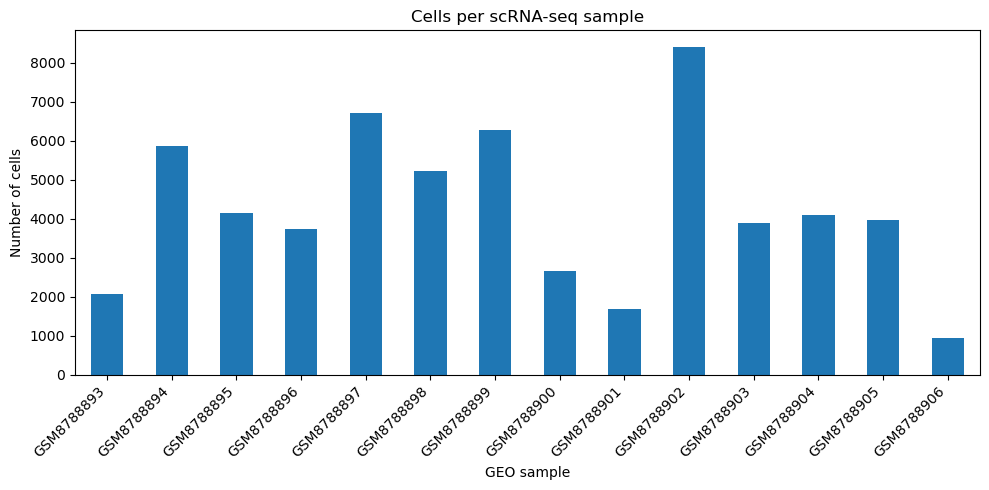

In [40]:
cells_per_sample.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.ylabel("Number of cells")
plt.xlabel("GEO sample")
plt.title("Cells per scRNA-seq sample")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Check genes detected per cell

In [41]:
adata.obs["n_genes_detected"] = np.asarray(
    (adata.X > 0).sum(axis=1)
).ravel()

In [42]:
adata.obs["n_genes_detected"].describe()

count    59632.000000
mean      1358.869550
std        889.431488
min        201.000000
25%        810.000000
50%       1136.000000
75%       1594.000000
max       5992.000000
Name: n_genes_detected, dtype: float64

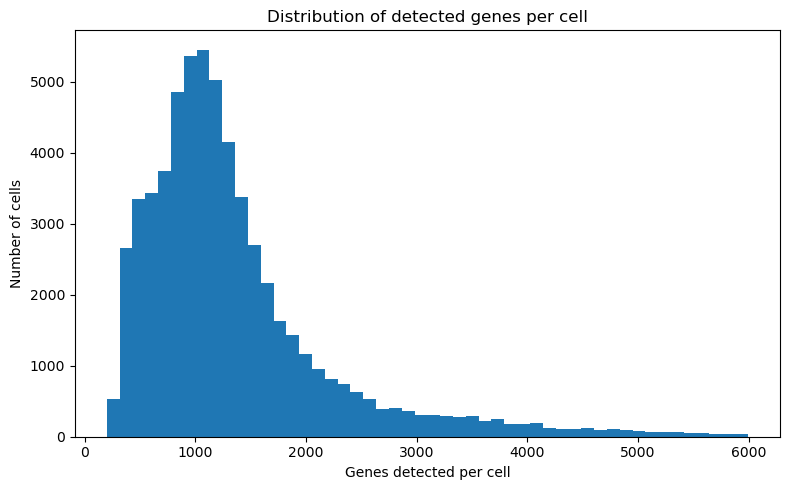

In [43]:
plt.figure(figsize=(8, 5))

plt.hist(
    adata.obs["n_genes_detected"],
    bins=50
)

plt.xlabel("Genes detected per cell")
plt.ylabel("Number of cells")
plt.title("Distribution of detected genes per cell")

plt.tight_layout()
plt.show()

## Look at detected genes by sample

In [44]:
adata.obs.groupby(
    "gsm",
    observed=True
)["n_genes_detected"].median().sort_values()

gsm
GSM8788901     461.5
GSM8788906     584.0
GSM8788894     841.0
GSM8788905     920.0
GSM8788899    1008.0
GSM8788900    1069.0
GSM8788893    1121.0
GSM8788896    1129.0
GSM8788898    1143.0
GSM8788904    1272.0
GSM8788895    1306.0
GSM8788897    1413.0
GSM8788902    1419.0
GSM8788903    1441.0
Name: n_genes_detected, dtype: float64

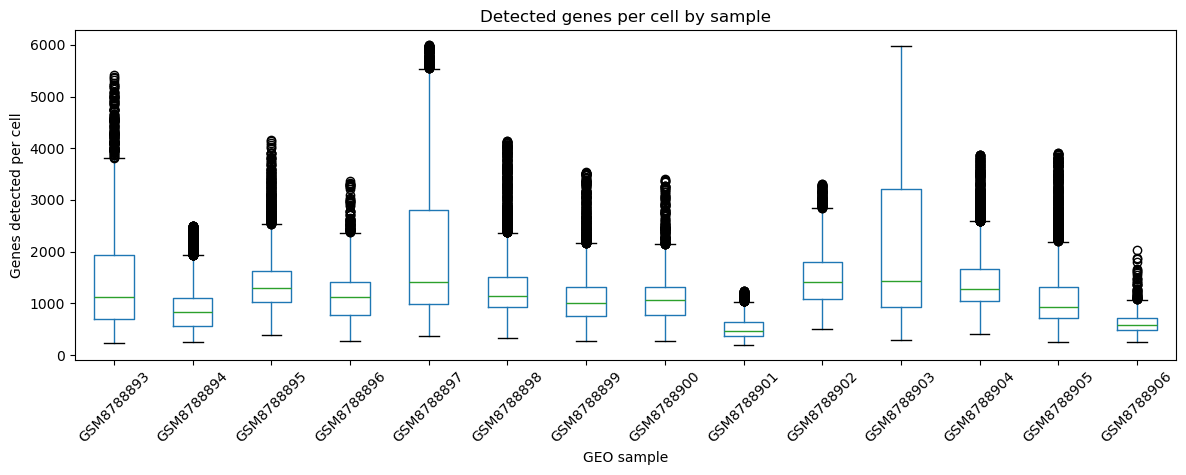

In [45]:
adata.obs.boxplot(
    column="n_genes_detected",
    by="gsm",
    figsize=(12, 5),
    rot=45,
    grid=False
)

plt.ylabel("Genes detected per cell")
plt.xlabel("GEO sample")
plt.title("Detected genes per cell by sample")
plt.suptitle("")
plt.tight_layout()
plt.show()

## Identify mitochondrial genes

In [46]:
adata.var["mt"] = adata.var_names.str.upper().str.startswith("MT-")

print("Mitochondrial genes:", adata.var["mt"].sum())

Mitochondrial genes: 13


In [47]:
adata.var_names[adata.var["mt"]][:20].tolist()

['MT-ND1',
 'MT-ND2',
 'MT-CO1',
 'MT-CO2',
 'MT-ATP8',
 'MT-ATP6',
 'MT-CO3',
 'MT-ND3',
 'MT-ND4L',
 'MT-ND4',
 'MT-ND5',
 'MT-ND6',
 'MT-CYB']

## Calculate a mitochondrial-expression fraction

In [48]:
total_expression = np.asarray(
    adata.X.sum(axis=1)
).ravel()

mt_expression = np.asarray(
    adata[:, adata.var["mt"]].X.sum(axis=1)
).ravel()

adata.obs["mt_expression_fraction"] = (
    mt_expression / total_expression
)

In [49]:
adata.obs["mt_expression_fraction"].describe()

count    59632.000000
mean         0.014888
std          0.007497
min          0.001332
25%          0.009937
50%          0.013444
75%          0.017731
max          0.085255
Name: mt_expression_fraction, dtype: float64

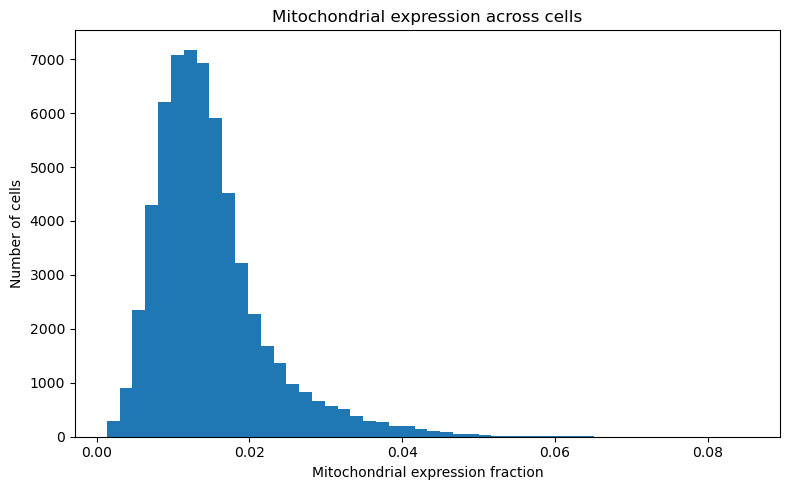

In [50]:
plt.figure(figsize=(8, 5))

plt.hist(
    adata.obs["mt_expression_fraction"],
    bins=50
)

plt.xlabel("Mitochondrial expression fraction")
plt.ylabel("Number of cells")
plt.title("Mitochondrial expression across cells")

plt.tight_layout()
plt.show()

## QC summary table

In [51]:
qc_summary = (
    adata.obs
    .groupby(
        ["gsm", "patient_id", "tissue_site", "condition"],
        observed=True
    )
    .agg(
        n_cells=("gsm", "size"),
        median_genes=("n_genes_detected", "median"),
        mean_genes=("n_genes_detected", "mean"),
        median_mt_fraction=("mt_expression_fraction", "median")
    )
    .reset_index()
)

qc_summary

,gsm,patient_id,tissue_site,condition,n_cells,median_genes,mean_genes,median_mt_fraction
0,GSM8788893,Patient1,colon,tumor,2059,1121.0,1545.072365,0.015661
1,GSM8788894,Patient1,colon,paracancerous,5873,841.0,905.456496,0.017869
2,GSM8788895,Patient2,colon,tumor,4136,1306.0,1392.615812,0.014380
3,GSM8788896,Patient2,colon,paracancerous,3723,1129.0,1134.646522,0.016912
4,GSM8788897,Patient3,colon,tumor,6698,1413.0,2007.958644,0.009666
5,GSM8788898,Patient3,colon,paracancerous,5217,1143.0,1319.779567,0.014531
6,GSM8788899,Patient4,colon,tumor,6282,1008.0,1090.378223,0.014734
7,GSM8788900,Patient4,colon,paracancerous,2659,1069.0,1118.377962,0.018276
8,GSM8788901,Patient5,colon,tumor,1688,461.5,523.207938,0.015654
9,GSM8788902,Patient5,colon,paracancerous,8406,1419.0,1476.453961,0.009849


In [52]:
qc_summary.to_csv(
    PROJECT_ROOT / "results" / "tables" / "scrna_qc_summary.csv",
    index=False
)

## Final secondary QC audit

Because GSE289314 provides author-processed post-QC expression matrices additional quality assessment focused on data integrity, cell- and gene-level expression characteristics, sample consistency, and identification of extreme outliers rather than repeating raw UMI-based filtering.

In [53]:
print("Cells:", adata.n_obs)
print("Genes:", adata.n_vars)

print("Unique cell IDs:", adata.obs_names.is_unique)
print("Unique gene IDs:", adata.var_names.is_unique)

print("Missing patient IDs:", adata.obs["patient_id"].isna().sum())
print("Missing tissue sites:", adata.obs["tissue_site"].isna().sum())
print("Missing conditions:", adata.obs["condition"].isna().sum())
print("Missing GSM IDs:", adata.obs["gsm"].isna().sum())

Cells: 59632
Genes: 24414
Unique cell IDs: True
Unique gene IDs: True
Missing patient IDs: 0
Missing tissue sites: 0
Missing conditions: 0
Missing GSM IDs: 0


## Check for NaN, infinite, or negative values

In [54]:
X_data = adata.X.data

print("NaN values:", np.isnan(X_data).sum())
print("Infinite values:", np.isinf(X_data).sum())
print("Negative values:", np.sum(X_data < 0))

NaN values: 0
Infinite values: 0
Negative values: 0


## Check for completely empty cells

In [55]:
cell_expression_sum = np.asarray(
    adata.X.sum(axis=1)
).ravel()

adata.obs["total_expression"] = cell_expression_sum

print("Cells with zero total expression:",
      np.sum(cell_expression_sum == 0))

Cells with zero total expression: 0


## Check total normalized expression

In [56]:
adata.obs["total_expression"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
)

count    59632.000000
mean      2049.338177
std        614.982597
min        329.754135
1%         694.765366
5%         980.713122
25%       1653.991326
50%       2058.384155
75%       2483.918755
95%       3045.948679
99%       3323.700715
max       4102.582746
Name: total_expression, dtype: float64

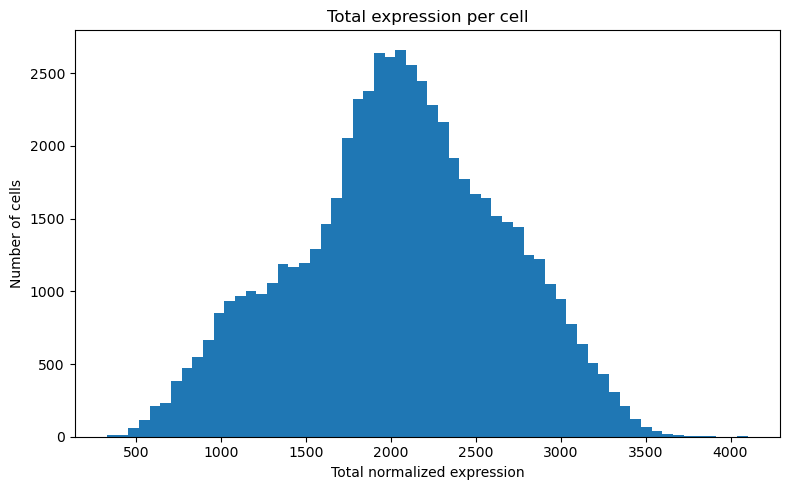

In [57]:
plt.figure(figsize=(8, 5))

plt.hist(
    adata.obs["total_expression"],
    bins=60
)

plt.xlabel("Total normalized expression")
plt.ylabel("Number of cells")
plt.title("Total expression per cell")

plt.tight_layout()
plt.show()

## Look at genes detected vs total expression

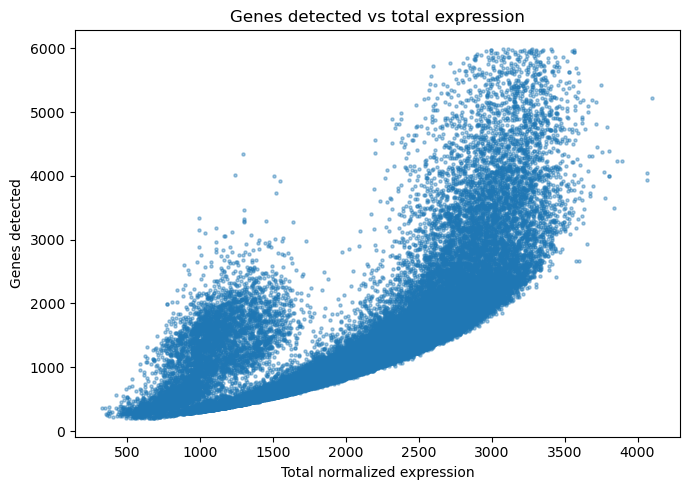

In [58]:
plt.figure(figsize=(7, 5))

plt.scatter(
    adata.obs["total_expression"],
    adata.obs["n_genes_detected"],
    s=5,
    alpha=0.4
)

plt.xlabel("Total normalized expression")
plt.ylabel("Genes detected")
plt.title("Genes detected vs total expression")

plt.tight_layout()
plt.show()

## Check mitochondrial expression by sample

In [59]:
mt_by_sample = (
    adata.obs
    .groupby("gsm", observed=True)["mt_expression_fraction"]
    .agg(["median", "mean", "max"])
    .sort_values("median")
)

mt_by_sample

,median,mean,max
gsm,,,
GSM8788897,0.009666,0.010277,0.037533
GSM8788902,0.009849,0.010661,0.035029
GSM8788904,0.010926,0.011333,0.036857
GSM8788903,0.012016,0.012499,0.066467
GSM8788905,0.013991,0.013656,0.074306
GSM8788895,0.014380,0.015274,0.051027
GSM8788898,0.014531,0.015137,0.063104
GSM8788899,0.014734,0.016486,0.084823
GSM8788901,0.015654,0.016511,0.046773


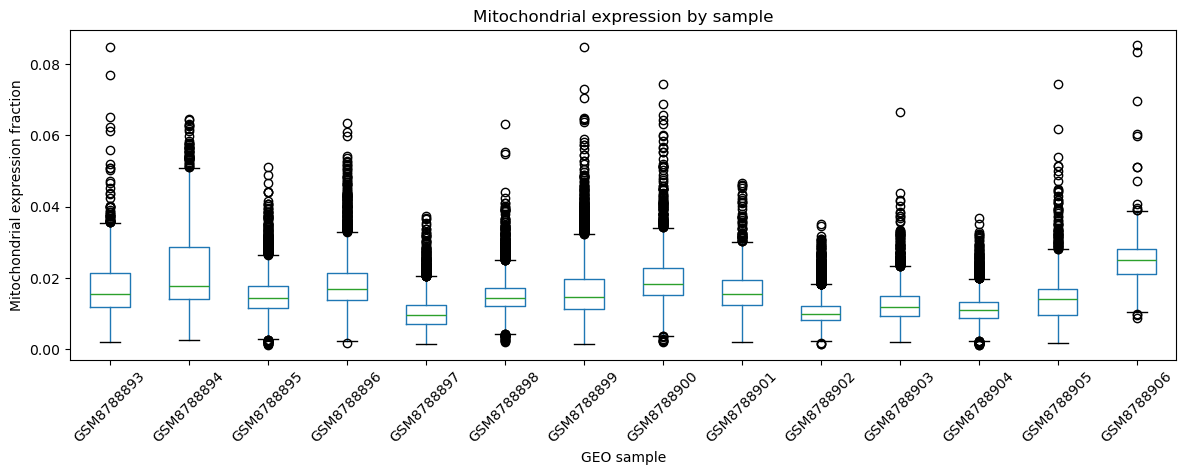

In [60]:
adata.obs.boxplot(
    column="mt_expression_fraction",
    by="gsm",
    figsize=(12, 5),
    rot=45,
    grid=False
)

plt.xlabel("GEO sample")
plt.ylabel("Mitochondrial expression fraction")
plt.title("Mitochondrial expression by sample")
plt.suptitle("")

plt.tight_layout()
plt.show()

## Check ribosomal gene expression

In [61]:
adata.var["ribo"] = (
    adata.var_names.str.upper().str.startswith("RPS")
    | adata.var_names.str.upper().str.startswith("RPL")
)

print("Ribosomal genes:", adata.var["ribo"].sum())

Ribosomal genes: 100


In [62]:
ribo_expression = np.asarray(
    adata[:, adata.var["ribo"]].X.sum(axis=1)
).ravel()

adata.obs["ribo_expression_fraction"] = (
    ribo_expression / adata.obs["total_expression"].values
)

In [63]:
adata.obs["ribo_expression_fraction"].describe()

count    59632.000000
mean         0.106512
std          0.035316
min          0.001366
25%          0.080579
50%          0.103611
75%          0.127997
max          0.395875
Name: ribo_expression_fraction, dtype: float64

In [64]:
adata.obs.groupby(
    "gsm",
    observed=True
)["ribo_expression_fraction"].median().sort_values()

gsm
GSM8788902    0.070855
GSM8788897    0.085744
GSM8788895    0.095037
GSM8788904    0.098668
GSM8788903    0.099415
GSM8788893    0.099777
GSM8788896    0.114328
GSM8788898    0.117621
GSM8788900    0.117760
GSM8788905    0.118038
GSM8788899    0.121815
GSM8788894    0.123564
GSM8788906    0.149625
GSM8788901    0.161127
Name: ribo_expression_fraction, dtype: float64

## Check gene detection across the dataset

In [65]:
cells_per_gene = np.asarray(
    (adata.X > 0).sum(axis=0)
).ravel()

adata.var["n_cells_detected"] = cells_per_gene
adata.var["pct_cells_detected"] = (
    cells_per_gene / adata.n_obs * 100
)

In [66]:
adata.var["n_cells_detected"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
)

count    24414.000000
mean      3319.083681
std       6665.179860
min          0.000000
1%           3.000000
5%           5.000000
25%         62.000000
50%        781.000000
75%       3537.750000
95%      14839.450000
99%      35213.500000
max      59314.000000
Name: n_cells_detected, dtype: float64

In [67]:
print(
    "Genes detected in zero cells:",
    (adata.var["n_cells_detected"] == 0).sum()
)

print(
    "Genes detected in fewer than 3 cells:",
    (adata.var["n_cells_detected"] < 3).sum()
)

Genes detected in zero cells: 5
Genes detected in fewer than 3 cells: 209


## Remove genes detected in zero cells

In [68]:
print("Before:", adata.shape)

adata = adata[:, adata.var["n_cells_detected"] > 0].copy()

print("After:", adata.shape)

Before: (59632, 24414)
After: (59632, 24409)


## Check cell numbers and QC metrics together by sample

In [69]:
qc_summary = (
    adata.obs
    .groupby(
        ["gsm", "patient_id", "tissue_site", "condition"],
        observed=True
    )
    .agg(
        n_cells=("gsm", "size"),
        median_genes_detected=("n_genes_detected", "median"),
        mean_genes_detected=("n_genes_detected", "mean"),
        median_total_expression=("total_expression", "median"),
        median_mt_fraction=("mt_expression_fraction", "median"),
        median_ribo_fraction=("ribo_expression_fraction", "median")
    )
    .reset_index()
)

qc_summary

,gsm,patient_id,tissue_site,condition,n_cells,median_genes_detected,mean_genes_detected,median_total_expression,median_mt_fraction,median_ribo_fraction
0,GSM8788893,Patient1,colon,tumor,2059,1121.0,1545.072365,1950.620378,0.015661,0.099777
1,GSM8788894,Patient1,colon,paracancerous,5873,841.0,905.456496,1699.947292,0.017869,0.123564
2,GSM8788895,Patient2,colon,tumor,4136,1306.0,1392.615812,2277.566433,0.014380,0.095037
3,GSM8788896,Patient2,colon,paracancerous,3723,1129.0,1134.646522,1959.106893,0.016912,0.114328
4,GSM8788897,Patient3,colon,tumor,6698,1413.0,2007.958644,2358.664985,0.009666,0.085744
5,GSM8788898,Patient3,colon,paracancerous,5217,1143.0,1319.779567,2011.377737,0.014531,0.117621
6,GSM8788899,Patient4,colon,tumor,6282,1008.0,1090.378223,1760.801477,0.014734,0.121815
7,GSM8788900,Patient4,colon,paracancerous,2659,1069.0,1118.377962,1932.834262,0.018276,0.117760
8,GSM8788901,Patient5,colon,tumor,1688,461.5,523.207938,1195.271481,0.015654,0.161127
9,GSM8788902,Patient5,colon,paracancerous,8406,1419.0,1476.453961,2538.486263,0.009849,0.070855


In [70]:
qc_summary.to_csv(
    PROJECT_ROOT / "results" / "tables" / "GSE289314_secondary_qc_summary.csv",
    index=False
)

## Check for extreme cells 

In [71]:
low_gene_cutoff = adata.obs["n_genes_detected"].quantile(0.01)
high_gene_cutoff = adata.obs["n_genes_detected"].quantile(0.99)

print("1st percentile genes:", low_gene_cutoff)
print("99th percentile genes:", high_gene_cutoff)

1st percentile genes: 322.0
99th percentile genes: 4853.690000000002


In [72]:
adata.obs["qc_extreme_gene_detection"] = (
    (adata.obs["n_genes_detected"] < low_gene_cutoff)
    | (adata.obs["n_genes_detected"] > high_gene_cutoff)
)

In [73]:
adata.obs["qc_extreme_gene_detection"].value_counts()

qc_extreme_gene_detection
False    58444
True      1188
Name: count, dtype: int64

In [74]:
pd.crosstab(
    adata.obs["gsm"],
    adata.obs["qc_extreme_gene_detection"]
)

qc_extreme_gene_detection,False,True
gsm,,
GSM8788893,1997,62
GSM8788894,5754,119
GSM8788895,4136,0
GSM8788896,3678,45
GSM8788897,6298,400
GSM8788898,5217,0
GSM8788899,6158,124
GSM8788900,2633,26
GSM8788901,1481,207


## Final QC checkpoint

In [75]:
print("FINAL SECONDARY QC SUMMARY")
print("--------------------------")
print("Cells:", adata.n_obs)
print("Genes:", adata.n_vars)
print("Patients:", adata.obs["patient_id"].nunique())
print("Samples:", adata.obs["gsm"].nunique())
print("Unique cell IDs:", adata.obs_names.is_unique)
print("Unique gene IDs:", adata.var_names.is_unique)
print("NaN expression values:", np.isnan(adata.X.data).sum())
print("Infinite expression values:", np.isinf(adata.X.data).sum())
print("Negative expression values:", np.sum(adata.X.data < 0))
print("Zero-expression cells:", np.sum(
    np.asarray(adata.X.sum(axis=1)).ravel() == 0
))

FINAL SECONDARY QC SUMMARY
--------------------------
Cells: 59632
Genes: 24409
Patients: 6
Samples: 14
Unique cell IDs: True
Unique gene IDs: True
NaN expression values: 0
Infinite expression values: 0
Negative expression values: 0
Zero-expression cells: 0


## Define matched scRNA-seq reference cohort

The spatial transcriptomic dataset contains matched tumor samples from Patients 2, 4, and 6. Therefore, scRNA-seq tumor samples from the same patients were selected to create the primary matched single-cell reference for downstream spatial gene-expression imputation.

The complete author-processed scRNA-seq dataset was retained separately while the matched tumor subset was used as the primary reference cohort.

### Define the matched patients

In [76]:
matched_patients = ["Patient2", "Patient4", "Patient6"]

### Subset to primary colon tumor samples

In [77]:
adata_tumor = adata[
    adata.obs["patient_id"].isin(matched_patients)
    & (adata.obs["tissue_site"] == "colon")
    & (adata.obs["condition"] == "tumor")
].copy()

In [78]:
adata_tumor

AnnData object with n_obs × n_vars = 14385 × 24409
    obs: 'gsm', 'sample_id', 'patient_id', 'tissue_site', 'condition', 'n_genes_detected', 'mt_expression_fraction', 'total_expression', 'ribo_expression_fraction', 'qc_extreme_gene_detection'
    var: 'mt', 'ribo', 'n_cells_detected', 'pct_cells_detected'
    layers: None (.X)

### Verify which samples were selected

In [79]:
adata_tumor.obs[
    ["gsm", "sample_id", "patient_id", "tissue_site", "condition"]
].drop_duplicates().sort_values("patient_id")

,gsm,sample_id,patient_id,tissue_site,condition
GSM8788895_CA:AAACCTGAGAGTAATC-2,GSM8788895,GSM8788895_CA_after_QC,Patient2,colon,tumor
GSM8788899_ZhangjiawangT:AAACCTGAGCGATAGC-6,GSM8788899,GSM8788899_Patient4_T_after_QC,Patient4,colon,tumor
GSM8788905_changai:AAACCTGAGGAGTTTA-12,GSM8788905,GSM8788905_Patient6_T_after_QC,Patient6,colon,tumor


### Count cells per patient

In [80]:
tumor_cells_per_patient = (
    adata_tumor.obs
    .groupby("patient_id", observed=True)
    .size()
    .sort_index()
)

tumor_cells_per_patient

patient_id
Patient2    4136
Patient4    6282
Patient6    3967
dtype: int64

In [81]:
print("Matched tumor reference")
print("-----------------------")
print("Patients:", adata_tumor.obs["patient_id"].nunique())
print("Samples:", adata_tumor.obs["gsm"].nunique())
print("Cells:", adata_tumor.n_obs)
print("Genes:", adata_tumor.n_vars)

Matched tumor reference
-----------------------
Patients: 3
Samples: 3
Cells: 14385
Genes: 24409


### Check cell IDs are still unique

In [82]:
print("Unique cell IDs:", adata_tumor.obs_names.is_unique)
print("Unique gene IDs:", adata_tumor.var_names.is_unique)

Unique cell IDs: True
Unique gene IDs: True


### Recalculate gene detection within the tumor reference

In [83]:
tumor_gene_detection = np.asarray(
    (adata_tumor.X > 0).sum(axis=0)
).ravel()

adata_tumor.var["n_cells_detected_tumor"] = tumor_gene_detection

adata_tumor.var["pct_cells_detected_tumor"] = (
    tumor_gene_detection / adata_tumor.n_obs * 100
)

In [84]:
adata_tumor.var["n_cells_detected_tumor"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
)

count    24409.000000
mean       705.920972
std       1555.774196
min          0.000000
1%           0.000000
5%           0.000000
25%         10.000000
50%        129.000000
75%        692.000000
95%       3251.000000
99%       8477.040000
max      14298.000000
Name: n_cells_detected_tumor, dtype: float64

In [85]:
print(
    "Genes detected in zero tumor cells:",
    (adata_tumor.var["n_cells_detected_tumor"] == 0).sum()
)

print(
    "Genes detected in at least 1% of tumor cells:",
    (
        adata_tumor.var["pct_cells_detected_tumor"] >= 1
    ).sum()
)

Genes detected in zero tumor cells: 2170
Genes detected in at least 1% of tumor cells: 11907


### Remove genes absent from the matched tumor cohort

In [86]:
print("Before:", adata_tumor.shape)

adata_tumor = adata_tumor[
    :,
    adata_tumor.var["n_cells_detected_tumor"] > 0
].copy()

print("After:", adata_tumor.shape)

Before: (14385, 24409)
After: (14385, 22239)


### Create a matched paracancerous cohort

In [87]:
adata_paracancerous = adata[
    adata.obs["patient_id"].isin(matched_patients)
    & (adata.obs["tissue_site"] == "colon")
    & (adata.obs["condition"] == "paracancerous")
].copy()

In [88]:
adata_paracancerous.obs[
    ["gsm", "sample_id", "patient_id", "tissue_site", "condition"]
].drop_duplicates().sort_values("patient_id")

,gsm,sample_id,patient_id,tissue_site,condition
GSM8788896_N:AAACCTGAGATAGGAG-3,GSM8788896,GSM8788896_N_after_QC,Patient2,colon,paracancerous
GSM8788900_ZhangjiawangN:AAACCTGAGCGTGAGT-7,GSM8788900,GSM8788900_Patient4_N_after_QC,Patient4,colon,paracancerous
GSM8788906_aipang:AAACCTGCATCCAACA-13,GSM8788906,GSM8788906_Patient6_N_after_QC,Patient6,colon,paracancerous


### Save matched references

In [89]:
adata_tumor.write(
    PROCESSED_DIR / "GSE289314_matched_tumor_reference.h5ad"
)

adata_paracancerous.write(
    PROCESSED_DIR / "GSE289314_matched_paracancerous_reference.h5ad"
)

In [90]:
print(
    PROCESSED_DIR / "GSE289314_matched_tumor_reference.h5ad"
)

print(
    PROCESSED_DIR / "GSE289314_matched_paracancerous_reference.h5ad"
)

/Users/gracescanlan/Desktop/crc_spatial_transcriptomics/data/processed/GSE289314_matched_tumor_reference.h5ad
/Users/gracescanlan/Desktop/crc_spatial_transcriptomics/data/processed/GSE289314_matched_paracancerous_reference.h5ad


### Save a reference summary table

In [91]:
reference_summary = (
    adata_tumor.obs
    .groupby(
        ["gsm", "patient_id", "tissue_site", "condition"],
        observed=True
    )
    .agg(
        n_cells=("gsm", "size"),
        median_genes_detected=("n_genes_detected", "median"),
        median_mt_fraction=("mt_expression_fraction", "median")
    )
    .reset_index()
)

reference_summary

,gsm,patient_id,tissue_site,condition,n_cells,median_genes_detected,median_mt_fraction
0,GSM8788895,Patient2,colon,tumor,4136,1306.0,0.014380
1,GSM8788899,Patient4,colon,tumor,6282,1008.0,0.014734
2,GSM8788905,Patient6,colon,tumor,3967,920.0,0.013991


In [92]:
reference_summary.to_csv(
    PROJECT_ROOT
    / "results"
    / "tables"
    / "matched_tumor_reference_summary.csv",
    index=False
)

## QC conclusion

The complete GSE289314 scRNA-seq dataset underwent secondary quality assessment following the authors' preprocessing procedures. No major data integrity issues were identified.

For downstream analysis, tumor scRNA-seq samples corresponding to the patients represented in the spatial transcriptomic dataset (Patients 2, 4, and 6) were selected as the primary matched reference cohort.
 
The final matched tumor reference contained 14,385 cells and 22,239 detected genes across three patients. This reference was saved for downstream characterization and spatial gene-expression prediction.